# Detecção de linhas de plantio em imagens de VANT: feijão em estágio inicial

Base: pares de imagens **RGB** e **NIR** (infravermelho próximo) de um campo experimental de feijão (*dry bean*) em estágio inicial, voo de **25/06/2020**, do conjunto de Aslahishahri et al. (2021), *From RGB to NIR: Predicting of Near Infrared Reflectance from Visible Spectrum Aerial Images of Crops*, ICCV Workshops (CVPPA). Câmera MicaSense RedEdge, GSD de ~1,5 cm/pixel.

Neste estágio, cada parcela tem **3 linhas de plantio visíveis** (no estágio mais avançado, o dossel fecha e as linhas ficam escondidas). O foco do notebook é a **detecção das linhas**: orientação, espaçamento e falhas.

Das 416 imagens, foram selecionadas **28**, sem água, sem campo vazio e sem sobreposição entre si (`imagens/drybean-estagio-inicial/selecao.csv`). Oito delas serão anotadas manualmente para a avaliação.

### Etapa 1: Configurações

In [35]:
# ============================================================
# ETAPA 1 - Importações e configuração do pipeline
# ============================================================
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

SEED = 42  # semente fixa: mesmos sorteios em toda execução

# Caminhos relativos à pasta do notebook
DIR_DADOS  = Path("imagens/drybean-estagio-inicial")   # RGB-1/ e NIR-1/ com 416 pares de imagens
ARQ_SELECAO = DIR_DADOS / "selecao.csv"                 # as 28 imagens usadas no pipeline
DIR_RESULT = Path("resultados-feijao-inicial")
DIR_RESULT.mkdir(exist_ok=True)

# Todos os parâmetros num só lugar (a análise de sensibilidade vai variá-los)
CFG = {
    "gsd_m": 0.015,              # tamanho do pixel no solo (m/pixel): voo de 25/06/2020, mesma
                                 # altura do conjunto anterior (o artigo informa 12 a 18 mm/pixel)
    "frac_borda_invalida": 0.5,  # linha/coluna da borda é descartada se mais da metade dos
                                 # pixels tiver algum canal RGB zerado (artefato de alinhamento)
    "desloc_max_px": 2.0,        # deslocamento RGB x NIR acima disso gera um aviso
}

plt.rcParams["figure.dpi"] = 110

### Etapa 2: Leitura das imagens RGB e NIR

Para cada imagem selecionada, lemos as duas bandas e as deixamos **alinhadas pixel a pixel**, porque os índices que combinam RGB e NIR (como o NDVI) são calculados pixel a pixel:
- o NIR tem 1 pixel a mais em cada direção (799 × 1099 contra 798 × 1098), então é cortado para o tamanho do RGB;
- faixas de borda com o artefato de alinhamento das bandas (canal RGB zerado) são removidas, com o **mesmo recorte** nas duas bandas;
- o deslocamento residual entre as bandas é medido por **correlação de fase**, como verificação.

In [36]:
# ============================================================
# ETAPA 2 - Leitura das imagens RGB e NIR
# ============================================================
def ler_imagem(caminho, flag=cv2.IMREAD_COLOR):
    """Lê uma imagem (funciona com acentos no caminho, no Windows)."""
    dados = np.fromfile(str(caminho), dtype=np.uint8)
    img = cv2.imdecode(dados, flag)
    if img is None:
        raise FileNotFoundError(f"Não foi possível ler {caminho}")
    return img

def ler_rgb(caminho):
    """Imagem colorida em RGB (o OpenCV lê em BGR)."""
    return cv2.cvtColor(ler_imagem(caminho), cv2.COLOR_BGR2RGB)

def ler_nir(caminho):
    """Banda do infravermelho próximo (NIR), em tons de cinza.
    O arquivo tem 3 canais iguais; IMREAD_GRAYSCALE lê um só."""
    return ler_imagem(caminho, cv2.IMREAD_GRAYSCALE)

def caixa_valida(rgb, frac_max):
    """Caixa (y0, y1, x0, x1) sem as faixas de borda com algum canal zerado.

    As bandas da câmera multiespectral são sensores separados, alinhados depois do voo;
    onde uma banda não cobre a cena, o canal fica 0 (aparece como uma faixa colorida).
    """
    invalido = (rgb == 0).any(axis=2)
    frac_lin, frac_col = invalido.mean(axis=1), invalido.mean(axis=0)

    def contar(perfil):  # quantas linhas/colunas seguidas, a partir da borda, são inválidas
        n = 0
        while n < len(perfil) and perfil[n] > frac_max:
            n += 1
        return n

    return (contar(frac_lin), len(frac_lin) - contar(frac_lin[::-1]),
            contar(frac_col), len(frac_col) - contar(frac_col[::-1]))

def deslocamento_rgb_nir(rgb, nir):
    """Estima o deslocamento (dx, dy) entre RGB e NIR por correlação de fase.

    Usamos o canal verde, cujo padrão espacial (plantas claras, solo escuro) é o mais
    parecido com o do NIR. Valores de 1-2 px são normais neste conjunto.
    """
    g = rgb[..., 1].astype(np.float32) / 255
    n = nir.astype(np.float32) / 255
    janela = cv2.createHanningWindow(g.shape[::-1], cv2.CV_32F)
    (dx, dy), _ = cv2.phaseCorrelate(g, n, janela)
    return dx, dy

df_sel = pd.read_csv(ARQ_SELECAO).set_index("id")

imagens_rgb, imagens_nir = {}, {}   # id -> matriz (já alinhadas e recortadas)
linhas = []
for id_img in df_sel.index:
    rgb = ler_rgb(DIR_DADOS / "RGB-1" / f"{id_img}.png")    # 798 x 1098
    nir = ler_nir(DIR_DADOS / "NIR-1" / f"{id_img}.png")    # 799 x 1099: 1 px a mais
    nir = nir[:rgb.shape[0], :rgb.shape[1]]                  # mesmo tamanho do RGB
    y0, y1, x0, x1 = caixa_valida(rgb, CFG["frac_borda_invalida"])
    rgb, nir = rgb[y0:y1, x0:x1], nir[y0:y1, x0:x1]         # mesmo recorte nas duas bandas
    dx, dy = deslocamento_rgb_nir(rgb, nir)
    imagens_rgb[id_img], imagens_nir[id_img] = rgb, nir
    linhas.append({"id": id_img, "altura": rgb.shape[0], "largura": rgb.shape[1],
                   "y0": y0, "x0": x0,   # deslocamento do recorte (para alinhar as anotações)
                   "linhas_removidas": 798 - rgb.shape[0], "desloc_x": round(dx, 2),
                   "desloc_y": round(dy, 2)})

df_imagens = df_sel.join(pd.DataFrame(linhas).set_index("id"))
print(f"{len(df_imagens)} imagens lidas; {df_imagens['para_anotar'].sum()} serão anotadas.")
print(f"Área coberta por imagem: ~{1098 * CFG['gsd_m']:.1f} m x {798 * CFG['gsd_m']:.1f} m")
print(f"Imagens com bordas removidas: {list(df_imagens.index[df_imagens['linhas_removidas'] > 0])}")
desl = np.hypot(df_imagens["desloc_x"], df_imagens["desloc_y"])
print(f"Deslocamento RGB x NIR: mediana {desl.median():.2f} px, máximo {desl.max():.2f} px")
if (desl > CFG["desloc_max_px"]).any():
    print("ATENÇÃO, deslocamento alto em:", list(df_imagens.index[desl > CFG["desloc_max_px"]]))

28 imagens lidas; 8 serão anotadas.
Área coberta por imagem: ~16.5 m x 12.0 m
Imagens com bordas removidas: [26, 85, 124, 132, 343, 357, 375, 385, 397]
Deslocamento RGB x NIR: mediana 0.44 px, máximo 0.51 px


In [37]:
df_imagens.head()

,para_anotar,frac_vegetacao_aprox,altura,largura,y0,x0,linhas_removidas,desloc_x,desloc_y
id,,,,,,,,,
1,0,0.069,798,1098,0,0,0,0.38,-0.26
26,0,0.092,765,1098,0,0,33,0.43,-0.12
74,0,0.079,798,1098,0,0,0,0.26,-0.32
77,1,0.082,798,1098,0,0,0,0.21,-0.44
85,0,0.079,783,1098,0,0,15,0.36,-0.22


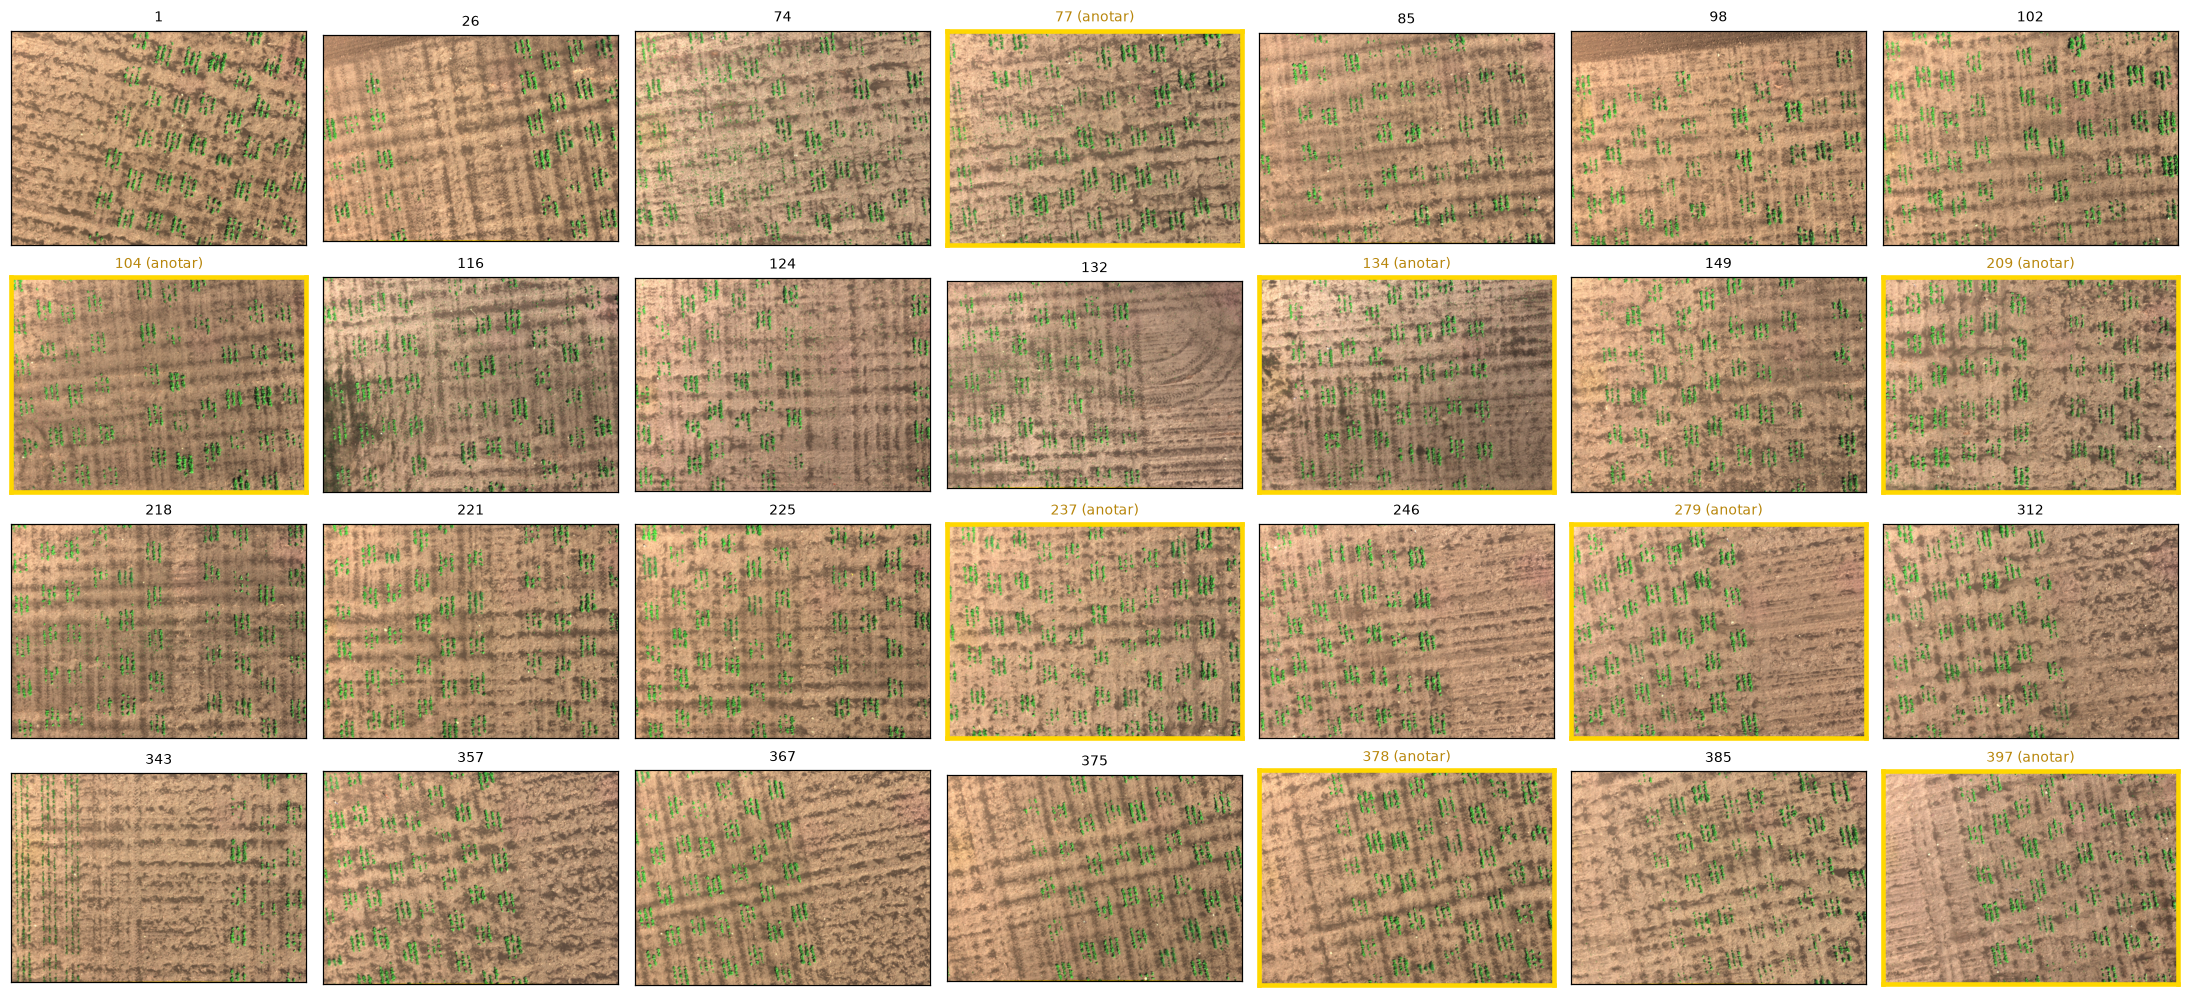

In [38]:
# Visão geral: as 28 imagens (moldura amarela = serão anotadas)
ids = list(imagens_rgb)
n_col = 7
n_lin = int(np.ceil(len(ids) / n_col))
fig, ax = plt.subplots(n_lin, n_col, figsize=(20, 2.3 * n_lin))
for a, id_img in zip(ax.ravel(), ids):
    a.imshow(imagens_rgb[id_img])
    anotar = df_imagens.loc[id_img, "para_anotar"] == 1
    a.set_title(f"{id_img}" + (" (anotar)" if anotar else ""), fontsize=9,
                color="#b8860b" if anotar else "k")
    if anotar:
        for s in a.spines.values():
            s.set_edgecolor("gold"); s.set_linewidth(3)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
    if not a.images:
        a.axis("off")
plt.tight_layout(); plt.show()

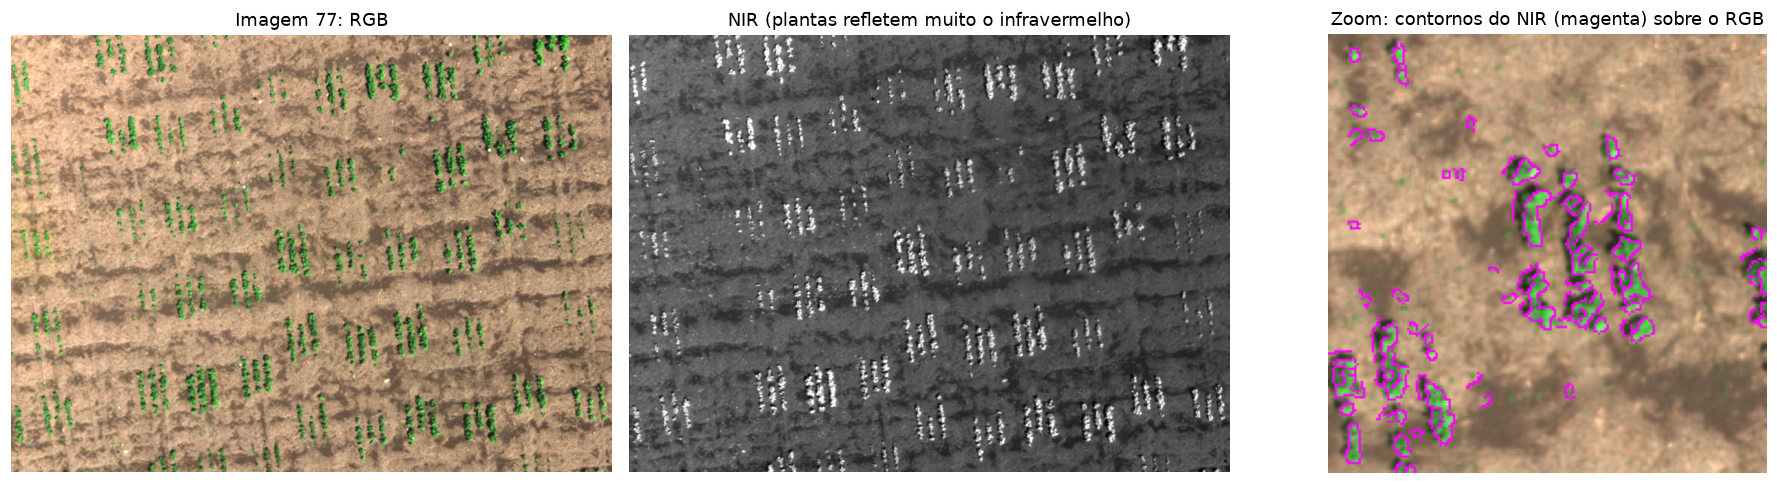

In [39]:
# RGB e NIR lado a lado em uma imagem, com zoom para conferir o alinhamento
id_ex = df_imagens.index[df_imagens["para_anotar"] == 1][0]
rgb, nir = imagens_rgb[id_ex], imagens_nir[id_ex]
y, x, t = 300, 400, 200   # região do zoom
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].imshow(rgb); ax[0].set_title(f"Imagem {id_ex}: RGB")
ax[1].imshow(nir, cmap="gray"); ax[1].set_title("NIR (plantas refletem muito o infravermelho)")
sobreposicao = rgb[y:y + t, x:x + t].copy()
borda_nir = cv2.Canny(cv2.GaussianBlur(nir[y:y + t, x:x + t], (5, 5), 0), 60, 120) > 0
sobreposicao[borda_nir] = (255, 0, 255)
ax[2].imshow(sobreposicao); ax[2].set_title("Zoom: contornos do NIR (magenta) sobre o RGB")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

### Etapa 3: Divisão em ajuste × teste

As 8 imagens anotadas são divididas em **ajuste** (3, para escolher métodos e parâmetros) e **teste** (5, para medir o desempenho final, sem tomar decisões). As outras 20 imagens não têm referência: o pipeline roda nelas para a análise qualitativa, mas elas não entram nas métricas.

In [40]:
# ============================================================
# ETAPA 3 - Divisão das imagens anotadas em ajuste x teste
# ============================================================
CFG["n_ajuste"] = 3   # das 8 imagens anotadas, 3 para ajustar parâmetros e 5 para testar

# As 20 imagens sem anotação não têm referência: servem para rodar o pipeline e
# para a análise qualitativa (onde ele funciona e onde falha), mas não entram nas métricas.
rng = np.random.default_rng(SEED)
anotadas = df_imagens.index[df_imagens["para_anotar"] == 1].to_numpy()
ajuste = rng.permutation(anotadas)[:CFG["n_ajuste"]]

df_imagens["conjunto"] = "sem referência"
df_imagens.loc[anotadas, "conjunto"] = "teste"
df_imagens.loc[ajuste, "conjunto"] = "ajuste"
df_imagens.to_csv(DIR_RESULT / "imagens.csv")

display(df_imagens["conjunto"].value_counts().to_frame("imagens"))
print("Ajuste:", sorted(df_imagens.index[df_imagens["conjunto"] == "ajuste"]))
print("Teste: ", sorted(df_imagens.index[df_imagens["conjunto"] == "teste"]))

,imagens
conjunto,
sem referência,20
teste,5
ajuste,3


Ajuste: [134, 209, 237]
Teste:  [77, 104, 279, 378, 397]


### Etapa 4: Máscara de vegetação (NDVI, ExG e fusão RGB + NIR)

Separa as plantas do solo. Como as imagens têm bom contraste, esta etapa é curta: comparamos 4 alternativas, todas sem parâmetros a ajustar:
- **NDVI + Otsu**: usa o NIR (a folha reflete muito o infravermelho e absorve o vermelho);
- **ExG + Otsu**: só RGB;
- **fusão por média**: NDVI e ExG normalizados, com o mesmo peso, + Otsu;
- **fusão por k-means** (k = 2) no espaço (NDVI, ExG).

Sem uma máscara de pixels de referência, a comparação usa as **linhas anotadas**, dentro da região de cada imagem de ajuste:
- **precisão espacial**: fração da vegetação detectada que está a até 6 px de uma linha anotada (o resto é ruído: textura do solo, plantas daninhas);
- **cobertura**: fração dos trechos com planta das linhas (fora das falhas) onde há vegetação detectada;
- **F1**: média harmônica das duas, usada para escolher a máscara.

In [41]:
# ============================================================
# ETAPA 4 - Máscara de vegetação: NDVI, ExG e fusão RGB + NIR
# ============================================================
import json

DIR_ANOT = Path("anotacoes-feijao-inicial")   # anotações manuais (protocolo v3)

CFG.update({
    "dist_linha_px": 6,      # pixel de vegetação a até 6 px (~9 cm) de uma linha anotada = "na linha"
    "raio_planta_px": 3,     # ponto da linha é "coberto" se houver vegetação a até 3 px dele
    "passo_amostra_px": 2,   # distância entre pontos amostrados ao longo das linhas
})

# --- Índices ---
def indice_ndvi(rgb, nir):
    """NDVI = (NIR - R) / (NIR + R). A folha reflete muito o infravermelho próximo e absorve
    o vermelho; o solo reflete os dois de forma parecida. O NIR vem em 8 bits sem calibração
    de reflectância, então os valores absolutos não são os 'padrão', mas o contraste é."""
    r = rgb[..., 0].astype(np.float32)
    n = nir.astype(np.float32)
    return (n - r) / (n + r + 1e-6)

def indice_exg(rgb):
    """Excess Green (Woebbecke et al., 1995): 2g - r - b, com r, g, b normalizados."""
    x = rgb.astype(np.float32)
    s = x.sum(axis=2) + 1e-6
    r, g, b = x[..., 0] / s, x[..., 1] / s, x[..., 2] / s
    return 2 * g - r - b

def normalizar(v, p_baixo=1, p_alto=99):
    """Reescala para [0, 1] pelos percentis: deixa NDVI e ExG na mesma escala para a fusão."""
    lo, hi = np.percentile(v, [p_baixo, p_alto])
    return np.clip((v - lo) / (hi - lo + 1e-12), 0, 1).astype(np.float32)

# --- Limiarização ---
def otsu(v):
    """Limiar de Otsu sobre um índice normalizado em [0, 1]."""
    _, m = cv2.threshold((v * 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m > 0

def kmeans_2(atributos, seed=SEED):
    """k-means (k = 2) nos atributos de cada pixel; vegetação = grupo de maior média."""
    h, w, n = atributos.shape
    X = atributos.reshape(-1, n).astype(np.float32)
    cv2.setRNGSeed(seed)
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 1e-3)
    _, rot, centros = cv2.kmeans(X, 2, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    return (rot.ravel() == np.argmax(centros.sum(axis=1))).reshape(h, w)

def mascaras_vegetacao(rgb, nir):
    """As 4 alternativas comparadas: {nome: máscara booleana}."""
    ndvi, exg = normalizar(indice_ndvi(rgb, nir)), normalizar(indice_exg(rgb))
    return {
        "NDVI + Otsu": otsu(ndvi),
        "ExG + Otsu": otsu(exg),
        "Fusão (média) + Otsu": otsu((ndvi + exg) / 2),         # RGB e NIR com o mesmo peso
        "Fusão k-means (NDVI, ExG)": kmeans_2(np.dstack([ndvi, exg])),
    }

# --- Anotações (coordenadas da imagem original -> imagem recortada na Etapa 2) ---
def carregar_anotacao(id_img):
    d = json.loads((DIR_ANOT / f"{id_img}.json").read_text(encoding="utf-8"))
    dy, dx = df_imagens.loc[id_img, ["y0", "x0"]]
    desloca = np.array([dx, dy, dx, dy], float)
    linhas = np.array(d["linhas"], float).reshape(-1, 4) - desloca
    falhas = np.array(d["falhas"], float).reshape(-1, 4) - desloca
    x0, y0, x1, y1 = np.array(d["regiao"], float) - desloca
    return linhas, falhas, (int(y0), int(y1), int(x0), int(x1))

**Métricas** a partir das linhas anotadas.

In [42]:
# --- Métricas a partir das linhas anotadas (dentro da região) ---
def mascara_proximo_das_linhas(linhas, forma, dist):
    """Pixels a até 'dist' px de alguma linha anotada (as linhas desenhadas com espessura)."""
    m = np.zeros(forma, np.uint8)
    for x1, y1, x2, y2 in np.round(linhas).astype(int):
        cv2.line(m, (x1, y1), (x2, y2), 1, 2 * dist + 1)
    return m > 0

def pontos_fora_das_falhas(linhas, falhas, passo):
    """Pontos ao longo das linhas anotadas que NÃO estão em falhas (onde deve haver planta)."""
    pts = []
    for x1, y1, x2, y2 in linhas:
        n = max(int(np.hypot(x2 - x1, y2 - y1) / passo), 1)
        t = np.linspace(0, 1, n + 1)
        p = np.column_stack([x1 + t * (x2 - x1), y1 + t * (y2 - y1)])
        for fx1, fy1, fx2, fy2 in falhas:   # remove os pontos que caem dentro de uma falha
            a, b = np.array([fx1, fy1]), np.array([fx2, fy2]); ab = b - a
            tt = np.clip(((p - a) @ ab) / (ab @ ab + 1e-12), 0, 1)
            p = p[np.linalg.norm(p - (a + tt[:, None] * ab), axis=1) > 2]
        pts.append(p)
    return np.round(np.vstack(pts)).astype(int)

def avaliar_mascara(mask, linhas, falhas, regiao, cfg=CFG):
    """- precisão espacial: fração da vegetação detectada (na região) que está sobre as linhas;
         baixa = muito ruído (textura do solo, plantas daninhas);
       - cobertura: fração dos trechos com planta das linhas onde há vegetação detectada;
         baixa = plantas perdidas (que viriam a ser falhas falsas)."""
    y0, y1, x0, x1 = regiao
    m = mask[y0:y1, x0:x1]
    desl = np.array([x0, y0, x0, y0], float)
    perto = mascara_proximo_das_linhas(linhas - desl, m.shape, cfg["dist_linha_px"])
    precisao = (m & perto).sum() / max(m.sum(), 1)
    k = 2 * cfg["raio_planta_px"] + 1
    m_dil = cv2.dilate(m.astype(np.uint8), np.ones((k, k), np.uint8)) > 0
    p = pontos_fora_das_falhas(linhas - desl, falhas - desl, cfg["passo_amostra_px"])
    p = p[(p[:, 0] >= 0) & (p[:, 0] < m.shape[1]) & (p[:, 1] >= 0) & (p[:, 1] < m.shape[0])]
    cobertura = m_dil[p[:, 1], p[:, 0]].mean()
    return {"precisao_espacial": precisao, "cobertura": cobertura,
            "F1": 2 * precisao * cobertura / (precisao + cobertura + 1e-12)}

**Visualização** das 4 máscaras em uma imagem de ajuste, com as linhas anotadas em amarelo.

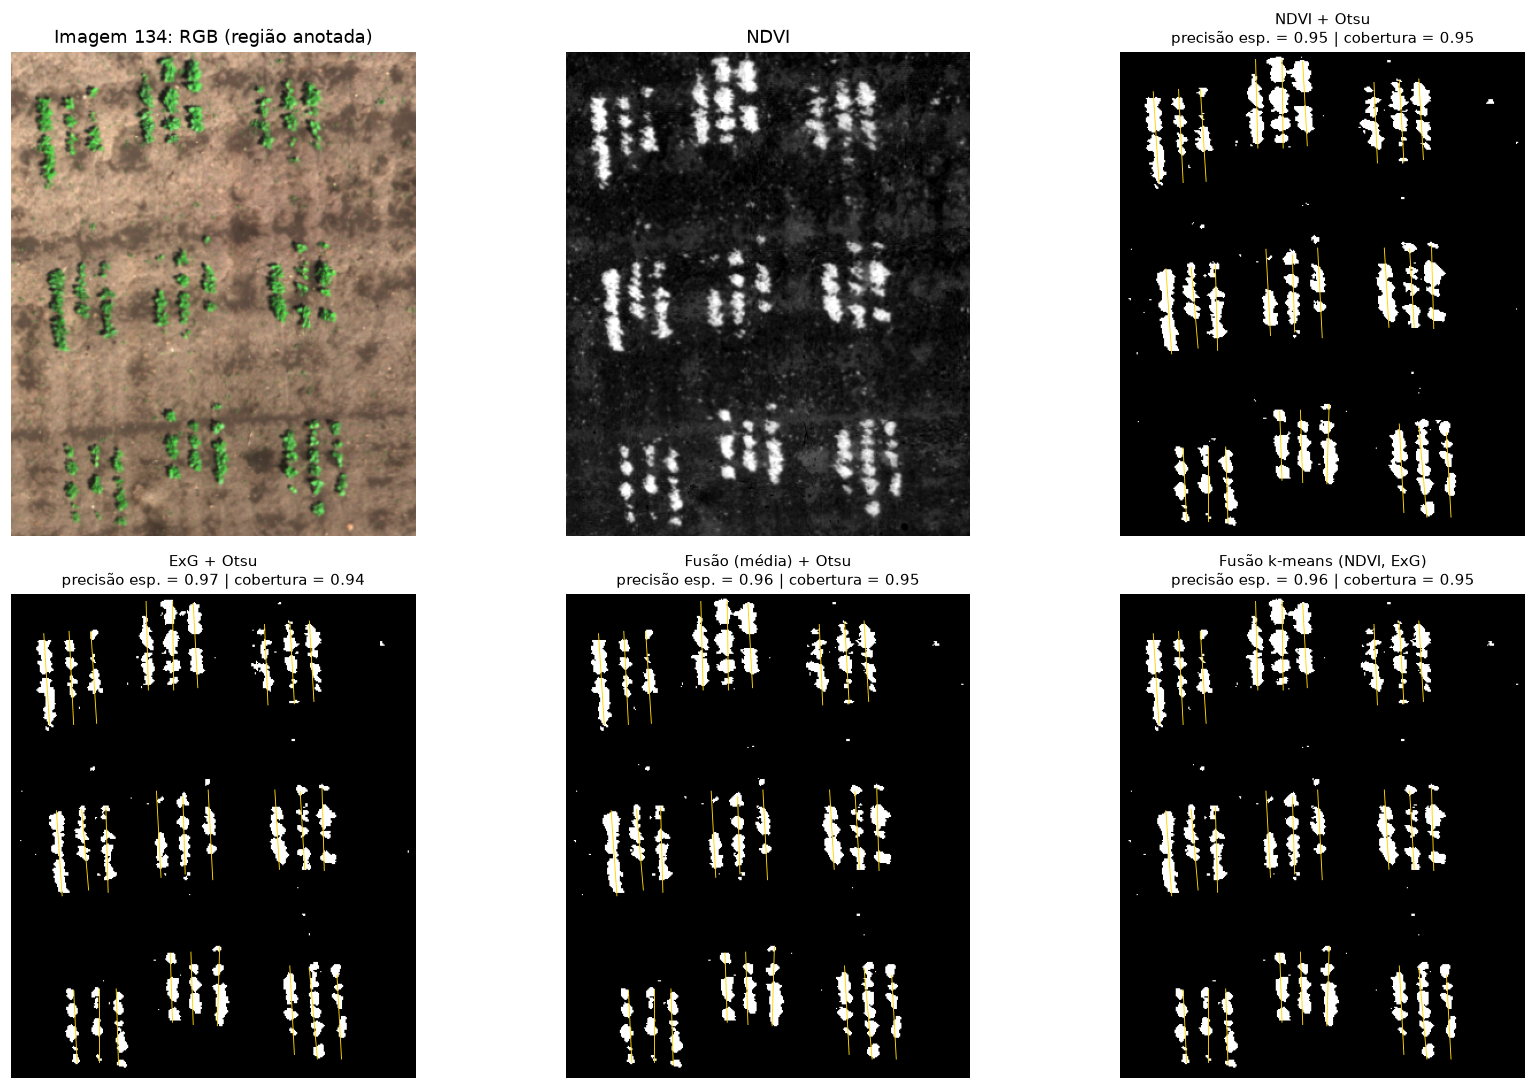

In [43]:
# --- Visualização em uma imagem de ajuste (dentro da região anotada) ---
id_ex = df_imagens.index[df_imagens["conjunto"] == "ajuste"][0]
rgb, nir = imagens_rgb[id_ex], imagens_nir[id_ex]
linhas_ex, falhas_ex, (y0, y1, x0, x1) = carregar_anotacao(id_ex)
masc = mascaras_vegetacao(rgb, nir)

fig, ax = plt.subplots(2, 3, figsize=(16, 10))
ax = ax.ravel()
ax[0].imshow(rgb[y0:y1, x0:x1]); ax[0].set_title(f"Imagem {id_ex}: RGB (região anotada)")
ax[1].imshow(normalizar(indice_ndvi(rgb, nir))[y0:y1, x0:x1], cmap="gray"); ax[1].set_title("NDVI")
for a, (nome, m) in zip(ax[2:], masc.items()):
    r = avaliar_mascara(m, linhas_ex, falhas_ex, (y0, y1, x0, x1))
    a.imshow(m[y0:y1, x0:x1], cmap="gray")
    for lx1, ly1, lx2, ly2 in linhas_ex - [x0, y0, x0, y0]:
        a.plot([lx1, lx2], [ly1, ly2], color="gold", lw=0.6)
    a.set_title(f"{nome}\nprecisão esp. = {r['precisao_espacial']:.2f} | cobertura = {r['cobertura']:.2f}",
                fontsize=10)
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

**Comparação nas imagens de ajuste** e escolha da máscara. A função `mascara_vegetacao` guarda a escolha para as próximas etapas.

In [44]:
# --- Comparação nas imagens de AJUSTE e escolha da máscara ---
linhas = []
for i in df_imagens.index[df_imagens["conjunto"] == "ajuste"]:
    lin, fal, reg = carregar_anotacao(i)
    for nome, m in mascaras_vegetacao(imagens_rgb[i], imagens_nir[i]).items():
        linhas.append({"imagem": i, "mascara": nome, **avaliar_mascara(m, lin, fal, reg)})
df_masc = pd.DataFrame(linhas)
df_masc.to_csv(DIR_RESULT / "mascaras_ajuste.csv", index=False)

tabela_masc = (df_masc.groupby("mascara")[["precisao_espacial", "cobertura", "F1"]].mean()
               .round(3).sort_values("F1", ascending=False))
display(tabela_masc)
display(df_masc.pivot(index="imagem", columns="mascara", values="F1").round(3))

CFG["mascara"] = tabela_masc.index[0]
print(f"Máscara escolhida (maior F1 médio no ajuste): {CFG['mascara']}")

def mascara_vegetacao(rgb, nir, cfg=CFG):
    """Máscara de vegetação final do pipeline (usada nas próximas etapas)."""
    return mascaras_vegetacao(rgb, nir)[cfg["mascara"]]

,precisao_espacial,cobertura,F1
mascara,,,
ExG + Otsu,0.969,0.947,0.958
Fusão (média) + Otsu,0.963,0.950,0.956
"Fusão k-means (NDVI, ExG)",0.962,0.950,0.956
NDVI + Otsu,0.950,0.950,0.950


mascara,ExG + Otsu,Fusão (média) + Otsu,"Fusão k-means (NDVI, ExG)",NDVI + Otsu
imagem,,,,
134,0.956,0.955,0.955,0.948
209,0.950,0.945,0.945,0.936
237,0.967,0.968,0.968,0.967


Máscara escolhida (maior F1 médio no ajuste): ExG + Otsu


### Etapa 5: Morfologia (limpar a máscara e consolidar as linhas)

A máscara da Etapa 4 tem ruído (pontos isolados) e cada linha aparece "picotada", planta por planta. Duas operações de morfologia matemática:
- **abertura** com um disco pequeno: remove pontos menores que o disco;
- **fechamento** com um elemento estruturante: emenda manchas separadas por espaços menores que o elemento.

**Alternativas comparadas:** elemento **vertical** (1 × n px, na direção das linhas) × **disco** (n px de diâmetro), com e sem abertura, variando n (análise de sensibilidade).

**Métricas** (região anotada das imagens de ajuste):
- **continuidade**: trechos com planta esperados pela anotação ÷ manchas encontradas sobre as linhas (1 = ideal);
- **preservação das falhas**: fração dos pontos das falhas anotadas que continuam sem planta;
- **fusão**: fração das manchas que tocam 2 ou mais linhas anotadas (linhas vizinhas grudadas).

In [45]:
# ============================================================
# ETAPA 5 - Morfologia: limpar a máscara e consolidar as linhas
# ============================================================
CFG.update({
    "abertura_px": 3,             # diâmetro do disco da abertura (remove pontos < ~3 px)
    "fechamento_forma": "vertical",
    "fechamento_px": 9,           # comprimento do elemento do fechamento (ajustado abaixo)
    "falha_min_px": 10,           # falhas anotadas menores que isso são ignoradas (protocolo v3)
    "fusao_max": 0.02,            # fração máxima aceitável de manchas que tocam 2+ linhas
})

def elemento_estruturante(forma, n):
    """'vertical': segmento de 1 x n pixels (na direção das linhas); 'disco': círculo de diâmetro n."""
    if forma == "vertical":
        return cv2.getStructuringElement(cv2.MORPH_RECT, (1, n))
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (n, n))

def aplicar_morfologia(mask, abertura_px, forma, n):
    """Abertura (remove pontos pequenos) seguida de fechamento (emenda plantas da mesma linha)."""
    m = mask.astype(np.uint8)
    if abertura_px > 1:
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, elemento_estruturante("disco", abertura_px))
    if n > 1:
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, elemento_estruturante(forma, n))
    return m > 0

# --- Métricas a partir das linhas e falhas anotadas (dentro da região) ---
def pontos_ao_longo(segs, passo=1, margem=0):
    """Pontos inteiros ao longo dos segmentos, sem os 'margem' px de cada ponta."""
    out = []
    for x1, y1, x2, y2 in segs:
        comp = np.hypot(x2 - x1, y2 - y1)
        if comp > 2 * margem:
            t = np.arange(margem, comp - margem + 1e-9, passo) / comp
            out.append(np.column_stack([x1 + t * (x2 - x1), y1 + t * (y2 - y1)]))
    return np.round(np.vstack(out)).astype(int) if out else np.empty((0, 2), int)

def trechos_esperados(linhas, falhas):
    """Quantos trechos com planta existem nas linhas anotadas: uma linha sem falhas é 1 trecho;
    uma falha no meio a divide em 2; uma falha na ponta não divide."""
    total = 0
    for seg in linhas:
        p = pontos_ao_longo([seg]).astype(float)
        em_falha = np.zeros(len(p), bool)
        for fx1, fy1, fx2, fy2 in falhas:
            a, b = np.array([fx1, fy1]), np.array([fx2, fy2]); ab = b - a
            t = np.clip(((p - a) @ ab) / (ab @ ab + 1e-12), 0, 1)
            em_falha |= np.linalg.norm(p - (a + t[:, None] * ab), axis=1) <= 2
        fora = ~em_falha                                   # começo de cada trecho com planta:
        total += int(fora[0]) + np.sum(fora[1:] & ~fora[:-1])
    return total

def metricas_morfologia(m, linhas, falhas, regiao, cfg=CFG, raio=2):
    """- continuidade: trechos esperados / manchas encontradas sobre as linhas (1 = perfeito;
         < 1 = linhas 'picotadas'; > 1 = falhas emendadas). Usamos min(r, 1/r) para punir os dois;
       - preservação de falhas: fração dos pontos das falhas anotadas que continuam sem planta;
       - fusão: fração das manchas sobre as linhas que tocam 2 ou mais linhas (linhas grudadas)."""
    y0, y1, x0, x1 = regiao
    mm = m[y0:y1, x0:x1].astype(np.uint8)
    d = np.array([x0, y0, x0, y0], float)
    lin = linhas - d
    fal = falhas - d
    fal = fal[np.hypot(fal[:, 2] - fal[:, 0], fal[:, 3] - fal[:, 1]) >= cfg["falha_min_px"]]

    # manchas (componentes conexos) e quais linhas anotadas cada uma toca
    rotulo_linha = np.zeros(mm.shape, np.int32)
    for k, (a, b, c, e) in enumerate(np.round(lin).astype(int), start=1):
        cv2.line(rotulo_linha, (a, b), (c, e), k, 1)
    _, manchas = cv2.connectedComponents(mm)
    sobre = rotulo_linha > 0
    pares = np.unique(np.column_stack([manchas[sobre], rotulo_linha[sobre]]), axis=0)
    pares = pares[pares[:, 0] > 0]                       # (mancha, linha), sem o fundo
    _, linhas_por_mancha = np.unique(pares[:, 0], return_counts=True)

    r = trechos_esperados(lin, fal) / max(len(pares), 1)
    continuidade = min(r, 1 / r) if r > 0 else 0.0

    k = 2 * raio + 1                                     # tolerância de 2 px à imprecisão da anotação
    perto = cv2.dilate(mm, np.ones((k, k), np.uint8)) > 0
    q = pontos_ao_longo(fal, 1, margem=3)
    q = q[(q[:, 0] >= 0) & (q[:, 0] < mm.shape[1]) & (q[:, 1] >= 0) & (q[:, 1] < mm.shape[0])]
    preservacao = 1 - perto[q[:, 1], q[:, 0]].mean() if len(q) else np.nan
    fusao = (linhas_por_mancha >= 2).mean() if len(linhas_por_mancha) else 0.0
    return {"continuidade": continuidade, "preservacao_falhas": preservacao, "fusao": fusao}

**Sensibilidade**: forma e tamanho do elemento do fechamento, com e sem abertura.

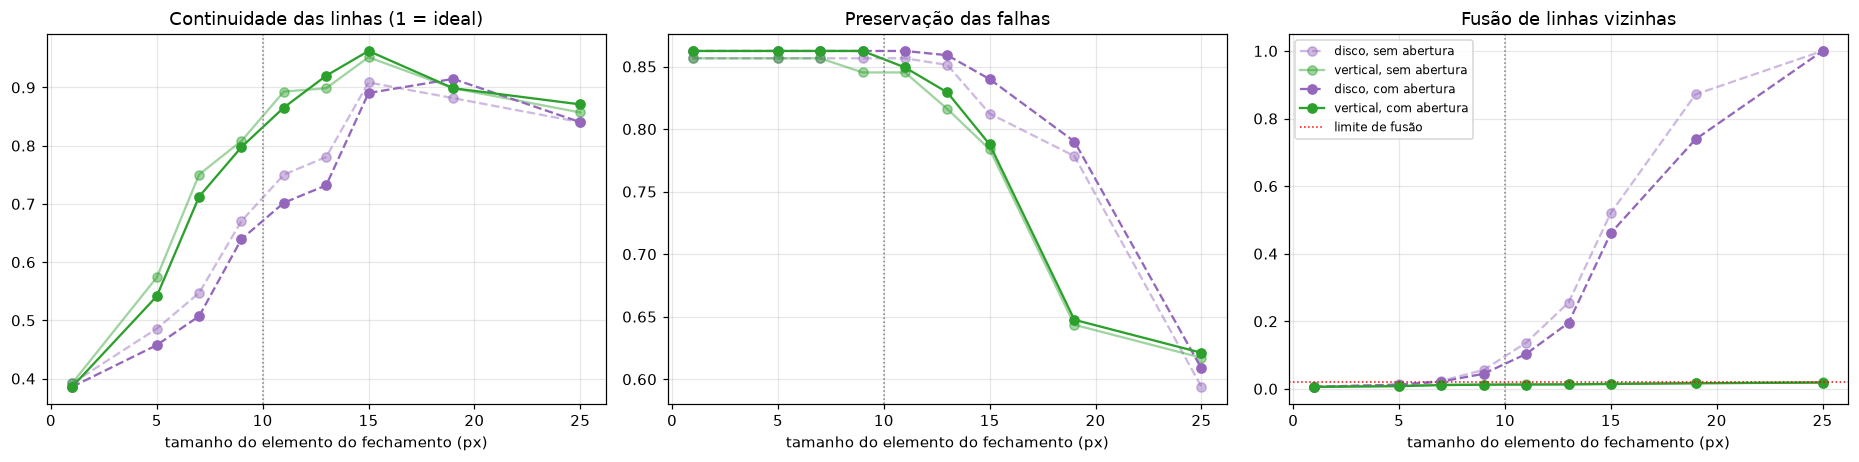

continuidade  preservacao_falhas  fusao  media_harm
abertura forma    n                                                      
False    disco    1          0.392               0.857  0.006       0.538
                  5          0.486               0.857  0.013       0.620
                  7          0.547               0.857  0.024       0.668
                  9          0.671               0.857  0.056       0.752
                  11         0.750               0.857  0.137       0.800
                  13         0.781               0.851  0.255       0.814
                  15         0.909               0.812  0.521       0.858
                  19         0.882               0.778  0.871       0.827
                  25         0.840               0.594  1.000       0.696
         vertical 1          0.392               0.857  0.006       0.538
                  5          0.574               0.857  0.009       0.687
                  7          0.750               0.857  0.012       0.800
                  9          0.808               0.845  0.013       0.826
                  11         0.893               0.845  0.013       0.868
                  13         0.899               0.816  0.013       0.855
                  15         0.952               0.784  0.014       0.860
                  19         0.899               0.644  0.017       0.750
                  25         0.857               0.617  0.020       0.718
True     disco    1          0.386               0.862  0.006       0.533
                  5          0.457               0.862  0.012       0.598
                  7          0.507               0.862  0.021       0.639
                  9          0.640               0.862  0.045       0.734
                  11         0.702               0.862  0.103       0.774
                  13         0.732               0.859  0.195       0.790
                  15         0.890               0.840  0.461       0.864
                  19         0.915               0.790  0.739       0.848
                  25         0.840               0.609  1.000       0.706
         vertical 1          0.386               0.862  0.006       0.533
                  5          0.542               0.862  0.008       0.665
                  7          0.713               0.862  0.011       0.780
                  9          0.798               0.862  0.012       0.829
                  11         0.865               0.849  0.013       0.857
                  13         0.920               0.829  0.013       0.872
                  15         0.963               0.788  0.014       0.866
                  19         0.899               0.648  0.017       0.753
                  25         0.871               0.621  0.019       0.725

In [46]:
# --- Sensibilidade: forma e comprimento do elemento do fechamento, com e sem abertura ---
ids_ajuste = df_imagens.index[df_imagens["conjunto"] == "ajuste"]
dados_aj = {i: (mascara_vegetacao(imagens_rgb[i], imagens_nir[i]), *carregar_anotacao(i))
            for i in ids_ajuste}

tamanhos = [1, 5, 7, 9, 11, 13, 15, 19, 25]   # n = 1: sem fechamento
linhas = []
for abertura in (0, CFG["abertura_px"]):
    for forma in ("vertical", "disco"):
        for n in tamanhos:
            for i, (m0, lin, fal, reg) in dados_aj.items():
                m = aplicar_morfologia(m0, abertura, forma, n)
                linhas.append({"imagem": i, "abertura": abertura > 1, "forma": forma, "n": n,
                               **metricas_morfologia(m, lin, fal, reg)})
df_morf = pd.DataFrame(linhas)
df_morf.to_csv(DIR_RESULT / "morfologia_ajuste.csv", index=False)

res = df_morf.groupby(["abertura", "forma", "n"])[["continuidade", "preservacao_falhas", "fusao"]].mean()
res["media_harm"] = (2 * res["continuidade"] * res["preservacao_falhas"]
                     / (res["continuidade"] + res["preservacao_falhas"]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for (abertura, forma), g in res.groupby(level=[0, 1]):
    g = g.droplevel([0, 1])
    estilo = "-" if forma == "vertical" else "--"
    cor = "tab:green" if forma == "vertical" else "tab:purple"
    rot = f"{forma}, {'com' if abertura else 'sem'} abertura"
    for a, col in zip(ax, ["continuidade", "preservacao_falhas", "fusao"]):
        a.plot(g.index, g[col], estilo, marker="o", color=cor, alpha=1 if abertura else 0.45, label=rot)
for a, titulo in zip(ax, ["Continuidade das linhas (1 = ideal)", "Preservação das falhas",
                          "Fusão de linhas vizinhas"]):
    a.axvline(CFG["falha_min_px"], color="gray", ls=":", lw=1)
    a.set_title(titulo); a.set_xlabel("tamanho do elemento do fechamento (px)"); a.grid(alpha=.3)
ax[2].axhline(CFG["fusao_max"], color="red", ls=":", lw=1, label="limite de fusão")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(res.round(3))

**Escolha** (só com o ajuste): maior média harmônica entre continuidade e preservação das falhas, entre as configurações com fusão ≤ 2%. A função `consolidar_linhas` guarda a escolha.

In [47]:
# --- Escolha (só com o ajuste): maior média harmônica entre continuidade e preservação,
#     entre as configurações que não grudam linhas vizinhas (fusão <= limite) ---
validas = res[res["fusao"] <= CFG["fusao_max"]]
melhor = validas["media_harm"].idxmax()
CFG["abertura_px"] = CFG["abertura_px"] if melhor[0] else 0
CFG["fechamento_forma"], CFG["fechamento_px"] = melhor[1], int(melhor[2])
print(f"Escolha: {'com' if melhor[0] else 'sem'} abertura, elemento {melhor[1]} de {melhor[2]} px")
display(validas.loc[[melhor]].round(3))

def consolidar_linhas(mask, cfg=CFG):
    """Morfologia final do pipeline (usada nas próximas etapas)."""
    return aplicar_morfologia(mask, cfg["abertura_px"], cfg["fechamento_forma"], cfg["fechamento_px"])

Escolha: com abertura, elemento vertical de 13 px


,,,continuidade,preservacao_falhas,fusao,media_harm
abertura,forma,n,,,,
True,vertical,13,0.92,0.829,0.013,0.872


**Visualização**: máscara antes e depois, e o disco do mesmo tamanho como comparação.

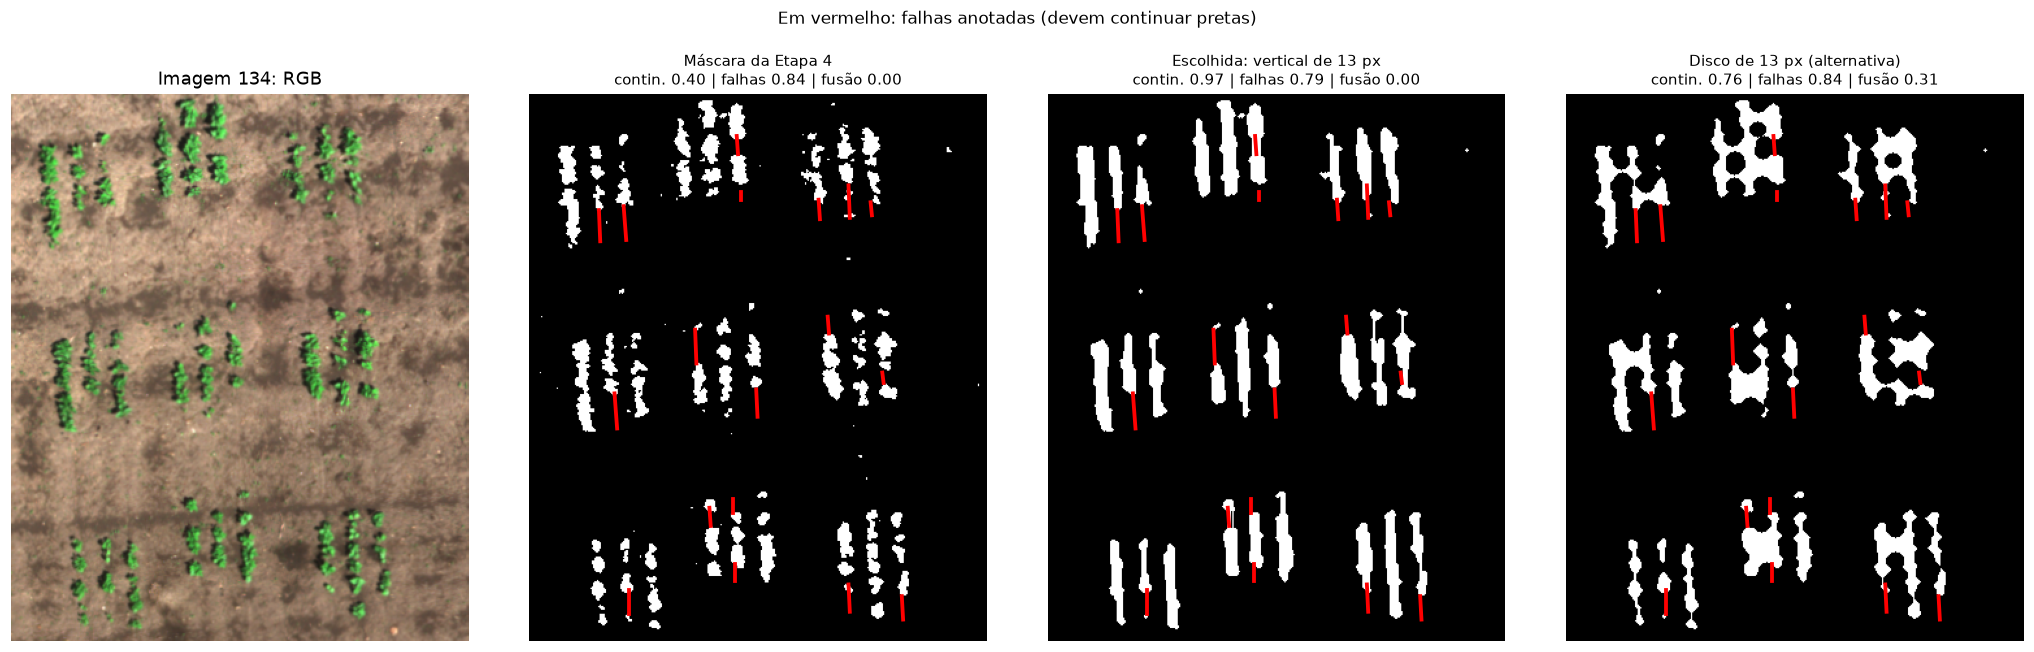

In [48]:
# --- Visualização: antes x depois, e o elemento vertical x disco do mesmo tamanho ---
id_ex = ids_ajuste[0]
m0, lin_ex, fal_ex, (y0, y1, x0, x1) = dados_aj[id_ex]
n = CFG["fechamento_px"]
versoes = {"Máscara da Etapa 4": m0,
           f"Escolhida: {CFG['fechamento_forma']} de {n} px": consolidar_linhas(m0),
           f"Disco de {n} px (alternativa)": aplicar_morfologia(m0, CFG["abertura_px"], "disco", n)}

fig, ax = plt.subplots(1, 4, figsize=(19, 6))
ax[0].imshow(imagens_rgb[id_ex][y0:y1, x0:x1]); ax[0].set_title(f"Imagem {id_ex}: RGB")
for a, (nome, m) in zip(ax[1:], versoes.items()):
    r = metricas_morfologia(m, lin_ex, fal_ex, (y0, y1, x0, x1))
    a.imshow(m[y0:y1, x0:x1], cmap="gray")
    for fx1, fy1, fx2, fy2 in fal_ex - [x0, y0, x0, y0]:
        a.plot([fx1, fx2], [fy1, fy2], color="red", lw=2.5)
    a.set_title(f"{nome}\ncontin. {r['continuidade']:.2f} | falhas {r['preservacao_falhas']:.2f} | "
                f"fusão {r['fusao']:.2f}", fontsize=10)
for a in ax:
    a.axis("off")
fig.suptitle("Em vermelho: falhas anotadas (devem continuar pretas)", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

### Etapa 6: Orientação das linhas (projeções × transformada de Hough)

Encontra o **ângulo das linhas de plantio** em cada imagem, a partir da máscara das Etapas 4 e 5. Ângulo medido a partir do eixo horizontal: linha vertical = 90°.

- **Projeções:** gira a máscara em vários ângulos e soma os pixels brancos de cada coluna. No ângulo certo, as linhas ficam em pé e a soma tem picos altos e vales fundos (maior variância).
- **Transformada de Hough:** cada pixel branco vota nas retas que passam por ele. Usamos a versão probabilística (`HoughLinesP`), que devolve segmentos de reta; o ângulo da imagem é a mediana dos ângulos dos segmentos.

**Métrica:** erro de orientação = diferença, em graus, entre o ângulo encontrado e a mediana dos ângulos das linhas anotadas.

In [49]:
# ============================================================
# ETAPA 6 - Orientação das linhas: projeções x transformada de Hough
# ============================================================
# Convenção: ângulo da linha medido a partir do eixo horizontal da imagem, em graus.
# Linha em pé (vertical) = 90°. Nas imagens, as linhas ficam entre ~75° e ~95°,
# então os dois métodos procuram o ângulo entre 60° e 120°.
CFG.update({
    "angulo_min": 60,          # faixa de ângulos procurada (graus)
    "angulo_max": 120,
    "proj_passo": 0.5,         # projeções: de quanto em quanto grau testar
    "hough_votos_min": 20,     # Hough: votos (pixels alinhados) necessários para aceitar um segmento
    "hough_comp_min": 20,      # Hough: comprimento mínimo de um segmento (px)
    "hough_vao_max": 5,        # Hough: maior vão (px) permitido dentro de um segmento
})

def angulo_referencia(linhas):
    """Ângulo das linhas anotadas: a mediana dos ângulos de todos os segmentos amarelos."""
    dx = linhas[:, 2] - linhas[:, 0]
    dy = linhas[:, 3] - linhas[:, 1]
    angulos = np.degrees(np.arctan2(dy, dx)) % 180   # 0 a 180 graus (90 = vertical)
    return float(np.median(angulos))

# --- Método 1: projeções ---
def girar(img, graus):
    """Gira a imagem em torno do centro (graus positivos = sentido anti-horário)."""
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), graus, 1.0)
    return cv2.warpAffine(img, M, (w, h))

def orientacao_projecoes(mask, cfg=CFG):
    """Gira a máscara em vários ângulos e soma os pixels brancos de cada coluna.
    No ângulo certo, as linhas ficam em pé e a soma tem picos altos e vales fundos:
    medimos isso pela variância do perfil das colunas."""
    m = mask.astype(np.uint8)
    angulos = np.arange(cfg["angulo_min"], cfg["angulo_max"] + 1e-9, cfg["proj_passo"])
    variancias = []
    for a in angulos:
        girada = girar(m, a - 90)           # gira o necessário para uma linha de ângulo 'a' ficar em pé
        perfil = girada.sum(axis=0)         # soma de cada coluna
        variancias.append(perfil.var())
    return float(angulos[np.argmax(variancias)]), angulos, np.array(variancias)

# --- Método 2: transformada de Hough (versão probabilística, que devolve segmentos) ---
def orientacao_hough(mask, cfg=CFG):
    """Cada pixel branco vota nas retas que passam por ele. A versão probabilística do OpenCV
    (HoughLinesP) devolve SEGMENTOS: trechos com pelo menos 'hough_comp_min' px, sem vãos
    maiores que 'hough_vao_max' px. O ângulo da imagem é a mediana dos ângulos dos segmentos
    quase verticais (entre angulo_min e angulo_max)."""
    m = mask.astype(np.uint8)
    seg = cv2.HoughLinesP(m, 1, np.radians(0.5), cfg["hough_votos_min"],
                          minLineLength=cfg["hough_comp_min"], maxLineGap=cfg["hough_vao_max"])
    if seg is None:
        return np.nan, np.empty((0, 4))
    seg = seg.reshape(-1, 4).astype(float)                  # cada linha: x1, y1, x2, y2
    angulos = np.degrees(np.arctan2(seg[:, 3] - seg[:, 1], seg[:, 2] - seg[:, 0])) % 180
    dentro = (angulos >= cfg["angulo_min"]) & (angulos <= cfg["angulo_max"])
    if not dentro.any():
        return np.nan, np.empty((0, 4))
    return float(np.median(angulos[dentro])), seg[dentro]

**Os dois métodos nas imagens de ajuste**, variando o principal parâmetro de cada um (sensibilidade).

In [50]:
# --- Os dois métodos nas imagens de AJUSTE, com sensibilidade dos parâmetros ---
mascaras_finais = {i: consolidar_linhas(mascara_vegetacao(imagens_rgb[i], imagens_nir[i]))
                   for i in df_imagens.index}   # máscara das Etapas 4 + 5, em todas as imagens
ids_ajuste = df_imagens.index[df_imagens["conjunto"] == "ajuste"]
ref = {i: angulo_referencia(carregar_anotacao(i)[0]) for i in df_imagens.index[df_imagens["para_anotar"] == 1]}

linhas = []
for passo in [0.5, 1, 2]:
    for i in ids_ajuste:
        ang, _, _ = orientacao_projecoes(mascaras_finais[i], {**CFG, "proj_passo": passo})
        linhas.append({"metodo": "projeções", "parametro": f"passo {passo}°", "imagem": i,
                       "erro": abs(ang - ref[i])})
for comp in [10, 20, 30, 40, 55]:
    for i in ids_ajuste:
        ang, _ = orientacao_hough(mascaras_finais[i], {**CFG, "hough_comp_min": comp})
        linhas.append({"metodo": "Hough", "parametro": f"segmento >= {comp} px", "imagem": i,
                       "erro": abs(ang - ref[i])})
df_or_aj = pd.DataFrame(linhas)
print("Erro de orientação (graus) nas imagens de ajuste:")
display(df_or_aj.pivot_table(index=["metodo", "parametro"], columns="imagem", values="erro", sort=False)
        .assign(media=lambda d: d.mean(axis=1)).round(2))

Erro de orientação (graus) nas imagens de ajuste:


imagem                        134   209   237  media
metodo    parametro                                 
projeções passo 0.5°         1.06  1.50  1.76   1.44
          passo 1°           1.06  1.00  2.26   1.44
          passo 2°           1.06  2.00  1.26   1.44
Hough     segmento >= 10 px  0.17  0.00  0.74   0.30
          segmento >= 20 px  0.72  0.00  0.72   0.48
          segmento >= 30 px  0.88  0.00  1.25   0.71
          segmento >= 40 px  1.15  0.94  1.59   1.23
          segmento >= 55 px  1.27  0.92  1.88   1.36

**Visualização** em uma imagem de ajuste: a curva das projeções, o perfil das colunas no ângulo certo e errado, e os segmentos do Hough.

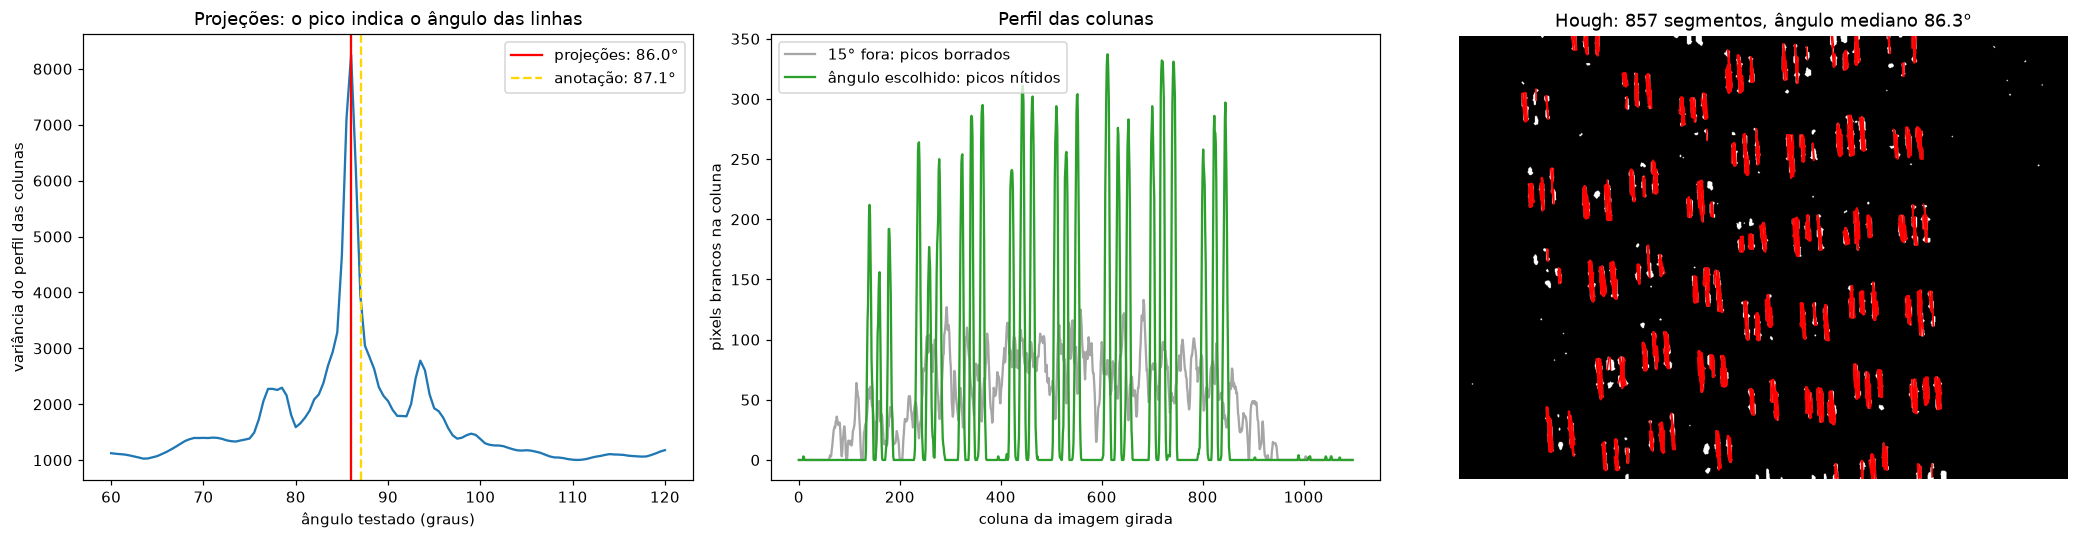

In [51]:
# --- Visualização em uma imagem de ajuste ---
id_ex = ids_ajuste[0]
m = mascaras_finais[id_ex]
ang_p, angulos, variancias = orientacao_projecoes(m)
ang_h, retas = orientacao_hough(m)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
# (a) curva das projeções: variância do perfil em cada ângulo
ax[0].plot(angulos, variancias)
ax[0].axvline(ang_p, color="red", label=f"projeções: {ang_p:.1f}°")
ax[0].axvline(ref[id_ex], color="gold", ls="--", label=f"anotação: {ref[id_ex]:.1f}°")
ax[0].set_xlabel("ângulo testado (graus)"); ax[0].set_ylabel("variância do perfil das colunas")
ax[0].set_title("Projeções: o pico indica o ângulo das linhas"); ax[0].legend()
# (b) perfil das colunas no ângulo errado x no ângulo certo
mu = m.astype(np.uint8)
ax[1].plot(girar(mu, (ang_p + 15) - 90).sum(axis=0), color="gray", alpha=.7, label="15° fora: picos borrados")
ax[1].plot(girar(mu, ang_p - 90).sum(axis=0), color="tab:green", label="ângulo escolhido: picos nítidos")
ax[1].set_xlabel("coluna da imagem girada"); ax[1].set_ylabel("pixels brancos na coluna")
ax[1].set_title("Perfil das colunas"); ax[1].legend()
# (c) segmentos encontrados pelo Hough sobre a máscara
ax[2].imshow(m, cmap="gray")
for x1, y1, x2, y2 in retas:
    ax[2].plot([x1, x2], [y1, y2], color="red", lw=1)
ax[2].axis("off")
ax[2].set_title(f"Hough: {len(retas)} segmentos, ângulo mediano {ang_h:.1f}°")
plt.tight_layout(); plt.show()

**Escolha dos parâmetros** (ajuste) e **avaliação final** nas imagens de teste.

In [52]:
# --- Escolha (ajuste) e avaliação final nas imagens de TESTE ---
media = df_or_aj.groupby(["metodo", "parametro"], sort=False)["erro"].mean()
print("Erro médio no ajuste:"); display(media.round(2).to_frame("erro médio (graus)"))
CFG["proj_passo"] = float(media["projeções"].idxmin().split()[1].rstrip("°"))
CFG["hough_comp_min"] = int(media["Hough"].idxmin().split()[-2])
print(f"Parâmetros escolhidos: passo das projeções = {CFG['proj_passo']}°, "
      f"comprimento mínimo dos segmentos do Hough = {CFG['hough_comp_min']} px")

linhas = []
for i in df_imagens.index[df_imagens["conjunto"] == "teste"]:
    ang_p, _, _ = orientacao_projecoes(mascaras_finais[i])
    ang_h, _ = orientacao_hough(mascaras_finais[i])
    linhas.append({"imagem": i, "referência": ref[i], "projeções": ang_p, "Hough": ang_h,
                   "erro projeções": abs(ang_p - ref[i]), "erro Hough": abs(ang_h - ref[i])})
df_or_te = pd.DataFrame(linhas).set_index("imagem")
df_or_te.to_csv(DIR_RESULT / "orientacao_teste.csv")
print("Imagens de TESTE (ângulos em graus):")
display(df_or_te.round(2))
print(f"Erro médio: projeções = {df_or_te['erro projeções'].mean():.2f}°, "
      f"Hough = {df_or_te['erro Hough'].mean():.2f}°")

Erro médio no ajuste:


erro médio (graus)
metodo    parametro                            
projeções passo 0.5°                       1.44
          passo 1°                         1.44
          passo 2°                         1.44
Hough     segmento >= 10 px                0.30
          segmento >= 20 px                0.48
          segmento >= 30 px                0.71
          segmento >= 40 px                1.23
          segmento >= 55 px                1.36

Parâmetros escolhidos: passo das projeções = 0.5°, comprimento mínimo dos segmentos do Hough = 10 px
Imagens de TESTE (ângulos em graus):


,referência,projeções,Hough,erro projeções,erro Hough
imagem,,,,,
77,83.62,83.0,84.05,0.62,0.43
104,86.53,85.0,85.60,1.53,0.93
279,83.24,82.5,83.16,0.74,0.08
378,77.55,78.0,78.69,0.45,1.14
397,79.11,79.0,79.10,0.11,0.01


Erro médio: projeções = 0.69°, Hough = 0.52°
